# 05. Модель «справедливой цены» квартиры (этап 6)

**Задача:** предсказать цену квартиры на продажу по её параметрам. Это нужно, чтобы:
1. понять, **на сколько процентов** каждый фактор (район, этаж, высотность, площадь) меняет цену;
2. находить **недооценённые объявления** — те, у которых цена заметно ниже прогноза модели.

**Модель:** линейная регрессия (`scikit-learn LinearRegression`) на **логарифме цены**.
Логарифм выбран, потому что цены скошены вправо, а факторы действуют в процентах: «Сарыарка дешевле
Есильского района на 30%», а не «на N тенге». Коэффициент `b` при категории переводится в проценты как `exp(b) − 1`.

**Признаки:** log(площадь), район, тип этажа, высотность дома, число комнат.
**Базовая категория** (с ней сравниваются остальные): Есильский район, средний этаж, дом 6–12 этажей, 2 комнаты.

In [1]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, r2_score
from sklearn.model_selection import KFold, cross_val_score, train_test_split

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 200)
RANDOM_STATE = 42

df = pd.read_pickle("data/clean_flats.pkl")
sale = df[(df["deal"] == "sale") & df["has_district"]].copy()
for col in ["district", "floor_type", "building_height"]:
    sale[col] = sale[col].astype(str)
sale["rooms_cat"] = sale["rooms_grp"].astype(int).map({1: "1", 2: "2", 3: "3", 4: "4+"})
sale["log_area"] = np.log(sale["area_m2"])
print(f"Квартир для модели: {len(sale)}")

Квартир для модели: 2878


## 1. Подготовка признаков

In [2]:
BASE = {"district": "Есильский", "floor_type": "Средний", "building_height": "Средняя (6–12)", "rooms_cat": "2"}

X = pd.get_dummies(sale[["log_area"] + list(BASE)], columns=list(BASE), dtype=float)
X = X.drop(columns=[f"{col}_{val}" for col, val in BASE.items()])

# Если этажность не указана, не указан и тип этажа — это один и тот же признак.
# Оставляем одну колонку, иначе возникает полная мультиколлинеарность.
X = X.drop(columns=["building_height_Не указан"])
X = X.rename(columns={"floor_type_Не указан": "этажность_не_указана"})

y = np.log(sale["price_kzt"])
print(f"Признаков: {X.shape[1]}")
list(X.columns)

Признаков: 14


['log_area',
 'district_Алматинский',
 'district_Байконур',
 'district_Нура',
 'district_Сарайшык',
 'district_Сарыарка',
 'этажность_не_указана',
 'floor_type_Первый',
 'floor_type_Последний',
 'building_height_Высотка (13+)',
 'building_height_Малоэтажка (до 5)',
 'rooms_cat_1',
 'rooms_cat_3',
 'rooms_cat_4+']

## 2. Обучение и точность

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
model = LinearRegression().fit(X_train, y_train)

pred_test = model.predict(X_test)
price_true, price_pred = np.exp(y_test), np.exp(pred_test)

r2_log = r2_score(y_test, pred_test)
r2_kzt = r2_score(price_true, price_pred)
mae = mean_absolute_error(price_true, price_pred)
mape = mean_absolute_percentage_error(price_true, price_pred)
cv = cross_val_score(LinearRegression(), X, y, cv=KFold(5, shuffle=True, random_state=RANDOM_STATE), scoring="r2")

print(f"R² (лог. цены, тест): {r2_log:.3f}")
print(f"R² (цена в тенге, тест): {r2_kzt:.3f}")
print(f"MAE: {mae / 1e6:.1f} млн ₸")
print(f"MAPE: {mape:.1%}")
print(f"Кросс-валидация R² (5 фолдов): {cv.mean():.3f} ± {cv.std():.3f}")

R² (лог. цены, тест): 0.813
R² (цена в тенге, тест): 0.742
MAE: 10.8 млн ₸
MAPE: 19.1%
Кросс-валидация R² (5 фолдов): 0.808 ± 0.010


**Вывод.** Модель объясняет **≈81% разброса** логарифма цены, и результат стабилен на кросс-валидации
(R² 0,79–0,82 на разных фолдах) — модель не переобучена. Средняя ошибка — **≈10,8 млн ₸ (≈19%)**.
Для оценки конкретной квартиры это много, но ожидаемо: в данных нет года постройки, состояния, ремонта
и вида из окна — а это главные причины разницы в цене внутри одного района. Поэтому модель годится
как **фильтр для брокера** («на эти объявления стоит посмотреть»), а не как оценщик.

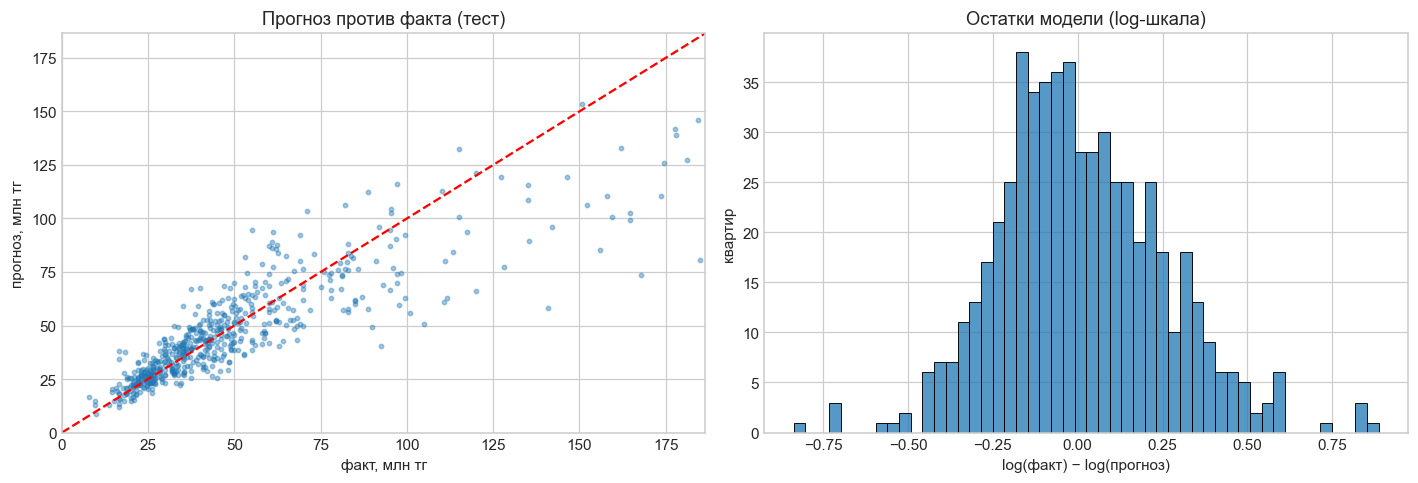

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(price_true / 1e6, price_pred / 1e6, s=8, alpha=0.4)
lim = [0, np.percentile(price_true / 1e6, 99)]
axes[0].plot(lim, lim, color="red", ls="--")
axes[0].set(xlim=lim, ylim=lim, title="Прогноз против факта (тест)", xlabel="факт, млн тг", ylabel="прогноз, млн тг")

resid = y_test - pred_test
sns.histplot(resid, bins=50, ax=axes[1])
axes[1].set(title="Остатки модели (log-шкала)", xlabel="log(факт) − log(прогноз)", ylabel="квартир")
plt.tight_layout(); plt.show()

**Вывод.** В бюджете до ≈75 млн ₸ точки лежат вдоль диагонали, остатки распределены симметрично вокруг нуля.
А вот **дорогие квартиры модель систематически недооценивает**: у них цену определяют факторы, которых нет в данных
(премиальный ЖК, вид, ремонт, паркинг). Для бюджета клиентов агентства (20–50 млн ₸) это не критично,
но для премиум-сегмента модель использовать нельзя.

## 3. Коэффициенты: сколько процентов добавляет каждый фактор

`LinearRegression` не считает p-value, поэтому стандартные ошибки и доверительные интервалы
считаем по классической формуле МНК на всех данных (`numpy` + `scipy`).

In [5]:
A = np.column_stack([np.ones(len(X)), X.values])
beta, *_ = np.linalg.lstsq(A, y.values, rcond=None)
resid_all = y.values - A @ beta
n, k = A.shape
sigma2 = resid_all @ resid_all / (n - k)
se = np.sqrt(np.diag(sigma2 * np.linalg.inv(A.T @ A)))
t = beta / se
p = 2 * stats.t.sf(np.abs(t), n - k)

coef = pd.DataFrame({"b": beta, "se": se, "p_value": p}, index=["const"] + list(X.columns)).drop(index="const")
coef["эффект_%"] = (np.exp(coef["b"]) - 1) * 100
coef["ДИ_95_низ_%"] = (np.exp(coef["b"] - 1.96 * coef["se"]) - 1) * 100
coef["ДИ_95_верх_%"] = (np.exp(coef["b"] + 1.96 * coef["se"]) - 1) * 100
coef["значим"] = coef["p_value"] < 0.05

print(f"Эластичность цены по площади: {coef.loc['log_area', 'b']:.2f} "
      f"(+1% площади → +{coef.loc['log_area', 'b']:.2f}% цены)")
effects = coef.drop(index="log_area").sort_values("эффект_%")
effects.style.format({"b": "{:.3f}", "se": "{:.3f}", "p_value": "{:.4f}",
                      "эффект_%": "{:+.1f}", "ДИ_95_низ_%": "{:+.1f}", "ДИ_95_верх_%": "{:+.1f}"})

Эластичность цены по площади: 0.99 (+1% площади → +0.99% цены)


,b,se,p_value,эффект_%,ДИ_95_низ_%,ДИ_95_верх_%,значим
district_Байконур,-0.401,0.028,0.0000,-33.0,-36.5,-29.3,True
district_Сарыарка,-0.365,0.017,0.0000,-30.6,-32.8,-28.2,True
district_Алматинский,-0.284,0.015,0.0000,-24.7,-26.9,-22.5,True
district_Сарайшык,-0.175,0.015,0.0000,-16.1,-18.5,-13.6,True
этажность_не_указана,-0.108,0.016,0.0000,-10.2,-13.0,-7.4,True
district_Нура,-0.104,0.011,0.0000,-9.9,-11.9,-7.8,True
floor_type_Последний,-0.079,0.015,0.0000,-7.6,-10.3,-4.7,True
floor_type_Первый,-0.063,0.026,0.0161,-6.1,-10.8,-1.2,True
building_height_Малоэтажка (до 5),-0.059,0.022,0.0063,-5.7,-9.7,-1.7,True
rooms_cat_1,-0.007,0.015,0.6157,-0.7,-3.6,+2.2,False


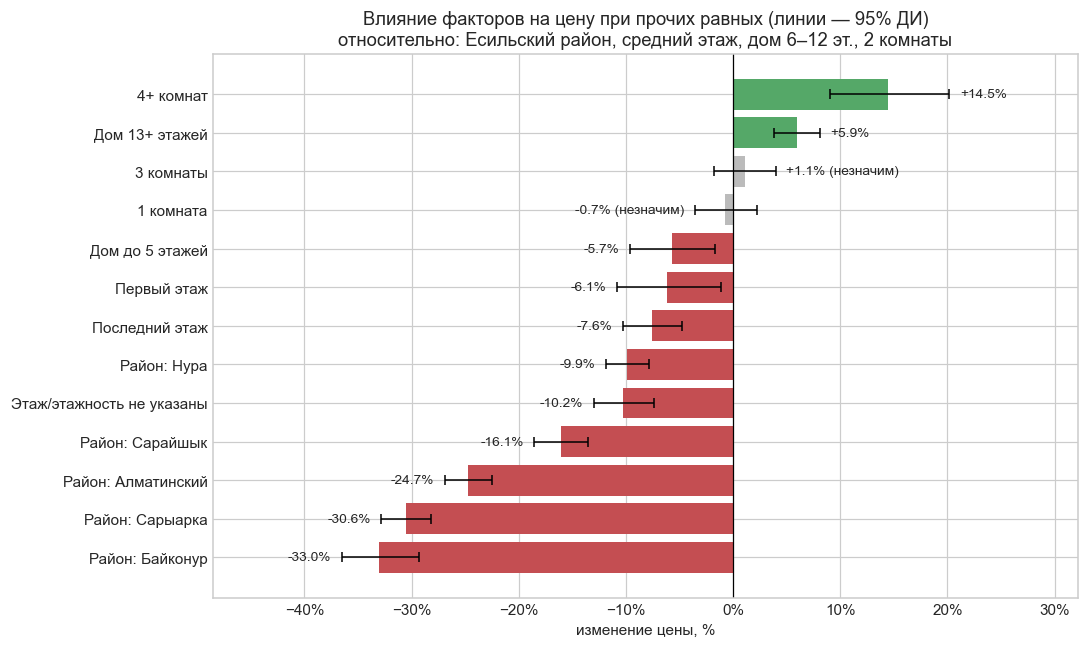

In [6]:
LABELS = {
    "district_Байконур": "Район: Байконур", "district_Сарыарка": "Район: Сарыарка",
    "district_Алматинский": "Район: Алматинский", "district_Сарайшык": "Район: Сарайшык",
    "district_Нура": "Район: Нура", "этажность_не_указана": "Этаж/этажность не указаны",
    "floor_type_Последний": "Последний этаж", "floor_type_Первый": "Первый этаж",
    "building_height_Малоэтажка (до 5)": "Дом до 5 этажей", "building_height_Высотка (13+)": "Дом 13+ этажей",
    "rooms_cat_1": "1 комната", "rooms_cat_3": "3 комнаты", "rooms_cat_4+": "4+ комнат",
}
plot = effects.rename(index=LABELS)

fig, ax = plt.subplots(figsize=(10, 6))
colors = ["#C44E52" if v < 0 else "#55A868" for v in plot["эффект_%"]]
colors = [c if sig else "#BBBBBB" for c, sig in zip(colors, plot["значим"])]
ax.barh(plot.index, plot["эффект_%"], color=colors)
ax.errorbar(plot["эффект_%"], range(len(plot)),
            xerr=[plot["эффект_%"] - plot["ДИ_95_низ_%"], plot["ДИ_95_верх_%"] - plot["эффект_%"]],
            fmt="none", ecolor="black", capsize=3, lw=1)
for i, row in enumerate(plot.itertuples()):
    v = row._4  # эффект_%
    edge = row._6 if v >= 0 else row._5  # верхняя / нижняя граница ДИ
    label = f"{v:+.1f}%" + ("" if row.значим else " (незначим)")
    ax.text(edge + (1 if v >= 0 else -1), i, label, va="center", ha="left" if v >= 0 else "right", fontsize=9)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlim(plot["ДИ_95_низ_%"].min() - 12, plot["ДИ_95_верх_%"].max() + 12)
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set(title="Влияние факторов на цену при прочих равных (линии — 95% ДИ)\n"
             "относительно: Есильский район, средний этаж, дом 6–12 эт., 2 комнаты",
       xlabel="изменение цены, %")
plt.tight_layout(); plt.show()

**Вывод.**
- **Площадь:** эластичность ≈ 1 — цена растёт почти пропорционально площади.
- **Район — главный фактор после площади.** При той же площади и этаже квартира в Байконуре и Сарыарке
  дешевле Есильского района на **≈31–33%**, в Алматинском — на ≈25%, в Сарайшыке — на ≈16%, в Нуре — на ≈10%.
- **Крайние этажи дешевле при прочих равных:** последний — на **≈7,5%** (95% ДИ: от −4,7% до −10,3%),
  первый — на **≈6%** (ДИ от −1% до −11%; первых этажей мало, интервал широкий). Это предварительно
  поддерживает **H3** — финальная проверка на этапе 7.
- **Высотность:** дом 13+ этажей дороже на **≈6%**, малоэтажка дешевле на ≈6% (относительно 6–12 этажей).
- **Если этаж не указан в объявлении, квартира в среднем на ≈10% дешевле** — продавцы чаще скрывают
  невыгодные характеристики. Полезный сигнал для брокера.
- **Число комнат 1–3 при той же площади цену не меняет** (эффекты незначимы) — важна площадь, а не планировка.
  Только 4+ комнаты дают премию (≈14%) — это премиальный сегмент.

## 4. Недооценённые объявления

In [7]:
THRESHOLD = 0.25   # объявление дешевле прогноза модели хотя бы на 25%

sale["fair_price"] = np.exp(model.predict(X))
sale["discount"] = (sale["fair_price"] - sale["price_kzt"]) / sale["fair_price"]
under = sale[(sale["discount"] >= THRESHOLD) & sale["in_client_budget"]]

print(f"Объявлений дешевле прогноза на {THRESHOLD:.0%}+: {(sale['discount'] >= THRESHOLD).sum()}, "
      f"из них в бюджете клиентов: {len(under)}")
display(under.groupby("district").size().sort_values(ascending=False).rename("недооценённых"))

Объявлений дешевле прогноза на 25%+: 280, из них в бюджете клиентов: 180


district
Есильский      64
Нура           57
Алматинский    24
Сарайшык       22
Сарыарка       10
Байконур        3
Name: недооценённых, dtype: int64

In [8]:
import glob
raw = pd.read_csv(sorted(glob.glob("data/raw/listings_*.csv"))[-1])
inv = pd.read_pickle("data/investment_metrics.pkl")[["listing_id", "net_yield", "payback_years"]]

candidates = (under.merge(inv, on="listing_id", how="left")
                   .merge(raw[["id", "url", "address"]].rename(columns={"id": "listing_id"}), on="listing_id", how="left")
                   .sort_values("discount", ascending=False))
cols = ["district", "rooms", "area_m2", "floor", "floors_total", "price_mln", "fair_price",
        "discount", "net_yield", "payback_years", "address", "url"]
candidates[cols].to_csv("data/undervalued_candidates.csv", index=False, encoding="utf-8-sig")
sale.to_pickle("data/sale_with_fair_price.pkl")

candidates[cols].head(15).style.format({"price_mln": "{:.1f}", "fair_price": lambda v: f"{v / 1e6:.1f}",
                                        "discount": "{:.0%}", "net_yield": "{:.1%}",
                                        "payback_years": "{:.1f}", "area_m2": "{:.0f}"})

,district,rooms,area_m2,floor,floors_total,price_mln,fair_price,discount,net_yield,payback_years,address,url
58,Есильский,3,100,12,14,39.0,78.1,50%,13.7%,7.3,"Есильский р-н, мкр Комсомольский, Чингиз Айтматов 36 — Сыганак",https://krisha.kz/a/show/1009380759
96,Нура,3,114,4,11,39.5,76.1,48%,14.9%,6.7,"Нура р-н, Туран 89/3",https://krisha.kz/a/show/1015259289
119,Нура,3,93,9,16,35.0,66.2,47%,13.8%,7.3,"Нура р-н, Кайым Мухамедханов 49",https://krisha.kz/a/show/1008830771
164,Алматинский,4,130,4,6,42.5,80.0,47%,17.8%,5.6,"Алматы р-н, Абылай хана 1",https://krisha.kz/a/show/1015934075
154,Есильский,2,120,6,9,48.0,86.9,45%,14.3%,7.0,"Есильский р-н, Сыганак 15 — Сауран",https://krisha.kz/a/show/1017053739
54,Есильский,3,85,10,13,37.5,66.9,44%,12.1%,8.2,"Есильский р-н, Чингиза Айтматова 36",https://krisha.kz/a/show/1008406094
69,Есильский,3,90,7,9,37.5,66.5,44%,12.8%,7.8,"Есильский р-н, Е923",https://krisha.kz/a/show/1014644399
82,Нура,3,110,11,13,44.0,77.4,43%,12.8%,7.8,"Нура р-н, мкр Уркер, Азильхан Нуршаихов 6",https://krisha.kz/a/show/1014369900
31,Нура,3,104,4,13,42.9,73.9,42%,12.6%,8.0,"Нура р-н, Е-15 9",https://krisha.kz/a/show/1015213531
27,Алматинский,3,99,11,13,34.0,58.1,41%,13.4%,7.5,"Алматы р-н, Майлина 6 — Между Сатпаева - Тауелсыздык",https://krisha.kz/a/show/1004035673


**Вывод.** Модель отмечает ≈180 объявлений в бюджете клиентов, которые дешевле «справедливой цены»
на 25% и больше. Файл `data/undervalued_candidates.csv` — **рабочий список для брокеров**.

**Ограничение, которое важно проговорить с агентством:** модель не знает о состоянии квартиры, годе постройки
и документах. Большая скидка к прогнозу может означать как выгодную сделку, так и квартиру без ремонта,
в старом доме или с проблемами. Список — это сигнал «посмотреть первым», а не готовая рекомендация.

## Итоги

| Показатель | Значение |
|---|---|
| R² на тесте (лог. цены) | ≈0,81 |
| R² кросс-валидации | ≈0,81 ± 0,01 |
| MAE | ≈10,8 млн ₸ |
| MAPE | ≈19% |

**Как улучшить модель:** добавить год постройки, материал дома, состояние и координаты (расстояние до центра,
Байтерека, парков). Эти поля есть на страницах объявлений — их можно собрать, когда krisha снимет ограничение,
медленным сбором деталей.